Raw shape: (284807, 31)
Missing values: 0
Duplicate rows: 1081
Rows:   284,807 -> 283,726 (removed 1,081)
Frauds: 492 -> 473
Fraud rate: 0.1667%
Class
0    283253
1       473
Name: count, dtype: int64
             Time      Amount
count 283726.0000 283726.0000
mean   94811.0776     88.4727
std    47481.0479    250.3994
min        0.0000      0.0000
25%    54204.7500      5.6000
50%    84692.5000     22.0000
75%   139298.0000     77.5100
max   172792.0000  25691.1600


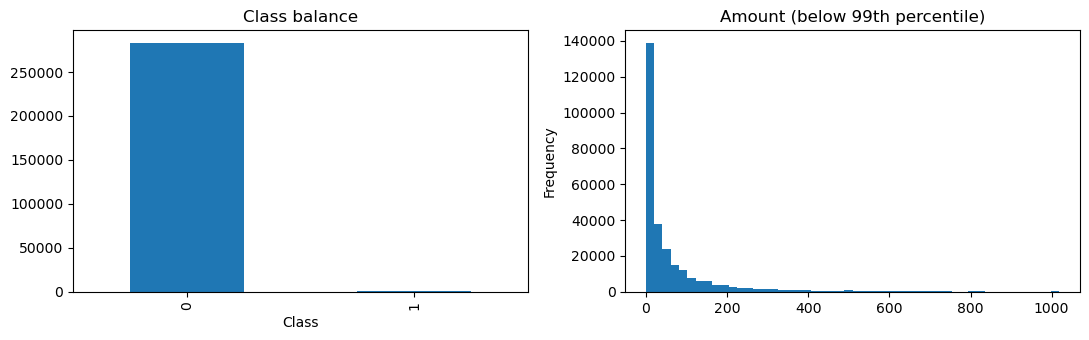

train rows=170,235  frauds= 284  rate=0.1668%
val   rows= 56,745  frauds=  94  rate=0.1657%
test  rows= 56,746  frauds=  95  rate=0.1674%

TOTAL rows=283,726  frauds=473
Split check passed.
            model  precision  recall     f1  pr_auc  roc_auc  TP   FP  FN    TN
   Dummy (priors)     0.0000  0.0000 0.0000  0.0017   0.5000   0    0  94 56651
LogReg (balanced)     0.0588  0.8511 0.1100  0.6922   0.9711  80 1280  14 55371


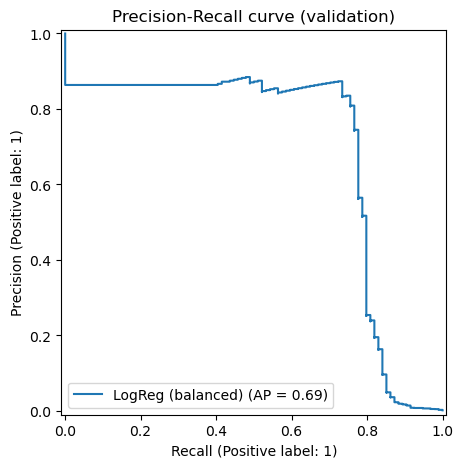

In [5]:
# %% [markdown]
# # Fraud Detection - Step 1 (v2): Load, DEDUPE, split, baselines
# Paste each "# %%" block into its own notebook cell and run them IN ORDER (Shift + Enter).
# Start from a fresh notebook, or clear the old cells first.

# %% [CELL 1] Imports and config
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score,
    confusion_matrix, PrecisionRecallDisplay,
)

SEED = 42
np.random.seed(SEED)

# Kaggle notebook: /kaggle/input/creditcardfraud/creditcard.csv
DATA_PATH = "creditcard.csv"

os.makedirs("results", exist_ok=True)

# %% [CELL 2] Load the data
df = pd.read_csv(DATA_PATH)
print("Raw shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

# %% [CELL 3] DEDUPE (must run BEFORE the split)
# Exact duplicate rows can land in both train and test, which inflates scores (data leakage).
before = len(df)
frauds_before = int(df["Class"].sum())

df = df.drop_duplicates().reset_index(drop=True)

print(f"Rows:   {before:,} -> {len(df):,} (removed {before - len(df):,})")
print(f"Frauds: {frauds_before} -> {int(df['Class'].sum())}")
print(f"Fraud rate: {df['Class'].mean():.4%}")
assert df.duplicated().sum() == 0

# %% [CELL 4] Quick EDA
print(df["Class"].value_counts())
print(df[["Time", "Amount"]].describe())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
df["Class"].value_counts().plot(kind="bar", ax=axes[0], title="Class balance")
df.loc[df["Amount"] < df["Amount"].quantile(0.99), "Amount"].plot(
    kind="hist", bins=50, ax=axes[1], title="Amount (below 99th percentile)"
)
plt.tight_layout()
plt.savefig("results/eda_overview.png", dpi=150)
plt.show()

# %% [CELL 5] Stratified split: 60% train / 20% validation / 20% test
X = df.drop(columns="Class")
y = df["Class"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)

for name, part in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:5s} rows={len(part):>7,}  frauds={int(part.sum()):>4}  rate={part.mean():.4%}")

# CHECK: these must match the de-duplicated data (about 283,726 rows and 473 frauds)
total_rows = len(y_train) + len(y_val) + len(y_test)
total_frauds = int(y_train.sum() + y_val.sum() + y_test.sum())
print(f"\nTOTAL rows={total_rows:,}  frauds={total_frauds}")
assert total_rows == len(df), "Split does not match df - re-run Cells 2, 3 and 5 in order."
assert total_frauds == int(df["Class"].sum())
print("Split check passed.")

# %% [CELL 6] Preprocessing (scaler is fit on training data only, inside the pipeline)
preprocess = ColumnTransformer(
    transformers=[("scale", StandardScaler(), ["Time", "Amount"])],
    remainder="passthrough",
)

# %% [CELL 7] Evaluation helper
def evaluate(name, model, X_eval, y_eval, threshold=0.5):
    """Metrics that matter for imbalanced fraud detection."""
    proba = model.predict_proba(X_eval)[:, 1]
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_eval, pred).ravel()
    return {
        "model": name,
        "precision": precision_score(y_eval, pred, zero_division=0),
        "recall": recall_score(y_eval, pred, zero_division=0),
        "f1": f1_score(y_eval, pred, zero_division=0),
        "pr_auc": average_precision_score(y_eval, proba),
        "roc_auc": roc_auc_score(y_eval, proba),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    }

# %% [CELL 8] Baselines: Dummy (no skill) and balanced Logistic Regression
dummy = Pipeline([
    ("prep", preprocess),
    ("clf", DummyClassifier(strategy="prior")),
]).fit(X_train, y_train)

logreg = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)),
]).fit(X_train, y_train)

results = pd.DataFrame([
    evaluate("Dummy (priors)", dummy, X_val, y_val),
    evaluate("LogReg (balanced)", logreg, X_val, y_val),
])

pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print(results.to_string(index=False))
results.to_csv("results/step1_baselines_validation.csv", index=False)

# %% [CELL 9] Precision-Recall curve (validation)
fig, ax = plt.subplots(figsize=(6, 5))
PrecisionRecallDisplay.from_estimator(logreg, X_val, y_val, name="LogReg (balanced)", ax=ax)
ax.set_title("Precision-Recall curve (validation)")
plt.savefig("results/pr_curve_logreg.png", dpi=150)
plt.show()

Guard passed. Train/val rows: 170235 56745
Train: 169,951 legit, 284 fraud -> scale_pos_weight = 598.4
done: RandomForest (balanced) (14.7s)
done: XGBoost (scale_pos_weight) (5.9s)
done: LogReg + SMOTE (1.3s)
done: XGBoost + SMOTE (7.9s)
                     model  precision  recall     f1  pr_auc  roc_auc  TP   FP  FN    TN  fit_seconds
   RandomForest (balanced)     0.9324  0.7340 0.8214  0.7997   0.9482  69    5  25 56646      14.7000
XGBoost (scale_pos_weight)     0.9250  0.7872 0.8506  0.7996   0.9778  74    6  20 56645       5.9000
           XGBoost + SMOTE     0.6116  0.7872 0.6884  0.7654   0.9638  74   47  20 56604       7.9000
         LogReg (balanced)     0.0588  0.8511 0.1100  0.6922   0.9711  80 1280  14 55371          NaN
            LogReg + SMOTE     0.0557  0.8511 0.1046  0.6909   0.9722  80 1355  14 55296       1.3000
            Dummy (priors)     0.0000  0.0000 0.0000  0.0017   0.5000   0    0  94 56651          NaN


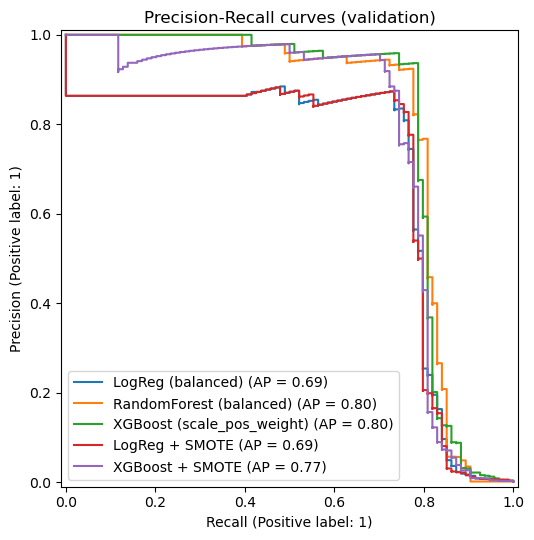

Best model by PR-AUC: RandomForest (balanced)
                                           model  precision  recall     f1  TP  FP  FN
        RandomForest (balanced) @ 0.50 (default)     0.9324  0.7340 0.8214  69   5  25
        RandomForest (balanced) @ 0.370 (max F1)     0.9241  0.7766 0.8439  73   6  21
RandomForest (balanced) @ 0.110 (precision>=80%)     0.8043  0.7872 0.7957  74  18  20


In [6]:
# %% [markdown]
# # Fraud Detection - Step 2 (v2): Better models, imbalance handling, threshold tuning
# Run in NEW cells BELOW Step 1 (v2) in the SAME notebook, in order.
# Reuses: df, X_train, X_val, y_train, y_val, preprocess, evaluate, results, logreg, SEED.
# Everything here is judged on the VALIDATION set. Do NOT touch X_test.

# %% [CELL 1] Imports and guard
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_curve, PrecisionRecallDisplay
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline   # keeps SMOTE on training data only
from imblearn.over_sampling import SMOTE

# Guard: the split must come from the de-duplicated data
assert len(X_train) + len(X_val) + len(X_test) == len(df), (
    "Stale split. Re-run Step 1 (v2) Cells 2, 3 and 5 in order, then continue."
)
print("Guard passed. Train/val rows:", len(X_train), len(X_val))

# %% [CELL 2] Define the candidate models
# Two ways to handle imbalance:
#   - class weights (model pays more attention to the rare fraud class)
#   - SMOTE (synthetic fraud examples, created on training data only)
neg, pos = int((y_train == 0).sum()), int((y_train == 1).sum())
spw = neg / pos
print(f"Train: {neg:,} legit, {pos} fraud -> scale_pos_weight = {spw:.1f}")


def make_xgb(**kw):
    return XGBClassifier(
        n_estimators=400, learning_rate=0.05, max_depth=5,
        subsample=0.8, colsample_bytree=0.8,
        eval_metric="aucpr", tree_method="hist",
        n_jobs=-1, random_state=SEED, **kw,
    )


candidates = {
    "RandomForest (balanced)": Pipeline([
        ("prep", clone(preprocess)),
        ("clf", RandomForestClassifier(
            n_estimators=200, min_samples_leaf=2,
            class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)),
    ]),
    "XGBoost (scale_pos_weight)": Pipeline([
        ("prep", clone(preprocess)),
        ("clf", make_xgb(scale_pos_weight=spw)),
    ]),
    "LogReg + SMOTE": ImbPipeline([
        ("prep", clone(preprocess)),
        ("smote", SMOTE(random_state=SEED)),
        ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
    ]),
    "XGBoost + SMOTE": ImbPipeline([
        ("prep", clone(preprocess)),
        ("smote", SMOTE(random_state=SEED)),
        ("clf", make_xgb()),
    ]),
}

# %% [CELL 3] Train and compare on validation (takes a minute or two)
fitted = {"LogReg (balanced)": logreg}
rows = []

for name, model in candidates.items():
    t0 = time.time()
    model.fit(X_train, y_train)
    fitted[name] = model
    row = evaluate(name, model, X_val, y_val)
    row["fit_seconds"] = round(time.time() - t0, 1)
    rows.append(row)
    print(f"done: {name} ({row['fit_seconds']}s)")

all_results = (
    pd.concat([results, pd.DataFrame(rows)], ignore_index=True)
      .sort_values("pr_auc", ascending=False)
      .reset_index(drop=True)
)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print(all_results.to_string(index=False))
all_results.to_csv("results/step2_model_comparison_validation.csv", index=False)

# %% [CELL 4] PR curves for every real model (validation)
fig, ax = plt.subplots(figsize=(7, 5.5))
for name, m in fitted.items():
    PrecisionRecallDisplay.from_estimator(m, X_val, y_val, name=name, ax=ax)
ax.set_title("Precision-Recall curves (validation)")
plt.tight_layout()
plt.savefig("results/pr_curves_all_models.png", dpi=150)
plt.show()

# %% [CELL 5] Threshold tuning on the best model (validation only)
#   A) threshold that maximises F1
#   B) threshold with the highest recall while keeping precision >= TARGET_PRECISION
# In real life this is a business decision: what does a missed fraud cost vs a false alarm?
TARGET_PRECISION = 0.80

best_name = all_results.iloc[0]["model"]
best_model = fitted[best_name]
print("Best model by PR-AUC:", best_name)

proba_val = best_model.predict_proba(X_val)[:, 1]
prec, rec, thr = precision_recall_curve(y_val, proba_val)

# precision/recall have one more entry than thresholds, so drop the last point
prec_t, rec_t = prec[:-1], rec[:-1]
f1_t = 2 * prec_t * rec_t / (prec_t + rec_t + 1e-12)

thr_f1 = float(thr[np.argmax(f1_t)])

mask = prec_t >= TARGET_PRECISION
thr_prec = float(thr[mask][np.argmax(rec_t[mask])]) if mask.any() else None

ops = [evaluate(f"{best_name} @ 0.50 (default)", best_model, X_val, y_val, 0.5)]
ops.append(evaluate(f"{best_name} @ {thr_f1:.3f} (max F1)", best_model, X_val, y_val, thr_f1))
if thr_prec is not None:
    ops.append(evaluate(
        f"{best_name} @ {thr_prec:.3f} (precision>={TARGET_PRECISION:.0%})",
        best_model, X_val, y_val, thr_prec))
else:
    print(f"No threshold reaches precision {TARGET_PRECISION:.0%}; lower TARGET_PRECISION.")

ops_df = pd.DataFrame(ops)
print(ops_df[["model", "precision", "recall", "f1", "TP", "FP", "FN"]].to_string(index=False))
ops_df.to_csv("results/step2_threshold_tuning_validation.csv", index=False)

# %% [markdown]
# ## What to write in your README after this step
# - Which model won on PR-AUC and by how much over the logistic regression baseline.
# - Did SMOTE help, or did class weights do just as well?
# - How false alarms dropped after threshold tuning, and what recall you gave up for it.
# - Caution: validation has only about 95 frauds, so small differences between models are noisy.
#
# Keep these variables for Step 3: best_name, best_model, thr_f1, thr_prec.

Guard passed. Total rows: 283726 | frauds: 473
Model: RandomForest (balanced) | chosen threshold: 0.370


C:\Users\arpit\AppData\Local\Temp\ipykernel_3020\3864077003.py:71: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, X_shap, show=False, max_display=15)


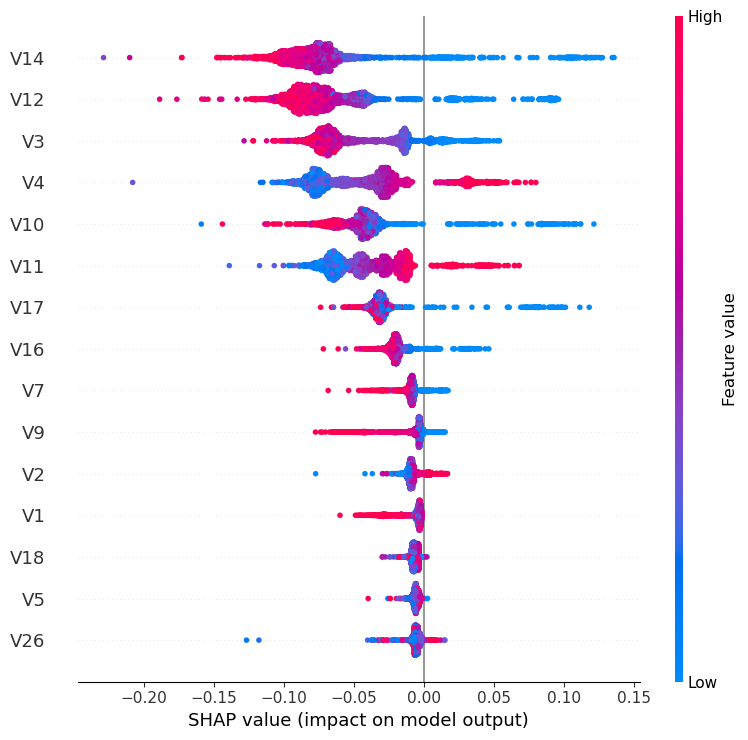

C:\Users\arpit\AppData\Local\Temp\ipykernel_3020\3864077003.py:77: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, X_shap, plot_type="bar", show=False, max_display=15)


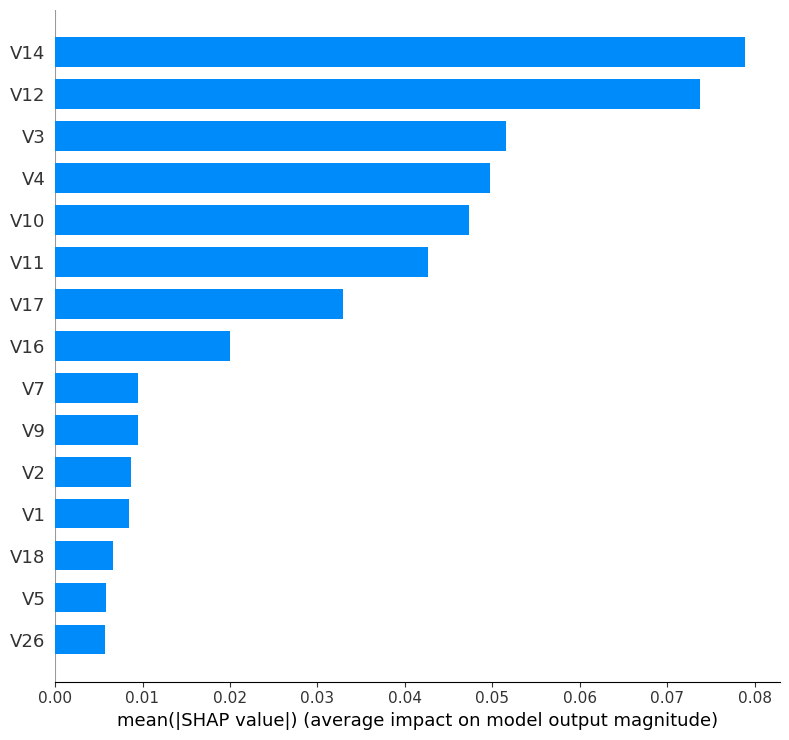

Top features by mean |SHAP|:
 V14   0.0790
V12   0.0738
V3    0.0515
V4    0.0498
V10   0.0473
V11   0.0426
V17   0.0330
V16   0.0200
dtype: float64
Caught frauds (TP): 73 | Missed frauds (FN): 21 | False alarms (FP): 6

Missed frauds (lowest score first):
              Time    Amount  y_true  proba  pred
130779  79540.0000    0.2000       1 0.0000     0
100242  67571.0000  549.0600       1 0.0000     0
273358 165981.0000    0.0000       1 0.0000     0
27256   34521.0000    1.5200       1 0.0000     0
107830  70828.0000    0.7600       1 0.0000     0
68371   53076.0000    1.1800       1 0.0000     0
101128  67857.0000  320.0000       1 0.0000     0
253455 156710.0000    7.5900       1 0.0000     0
244437 152710.0000    2.4700       1 0.0000     0
212341 139107.0000   22.4700       1 0.0050     0
175384 122608.0000 2125.8700       1 0.0050     0
67805   52814.0000  519.9000       1 0.0050     0
20129   30852.0000  104.8100       1 0.0050     0
58516   48533.0000    1.0000       1 0.0050

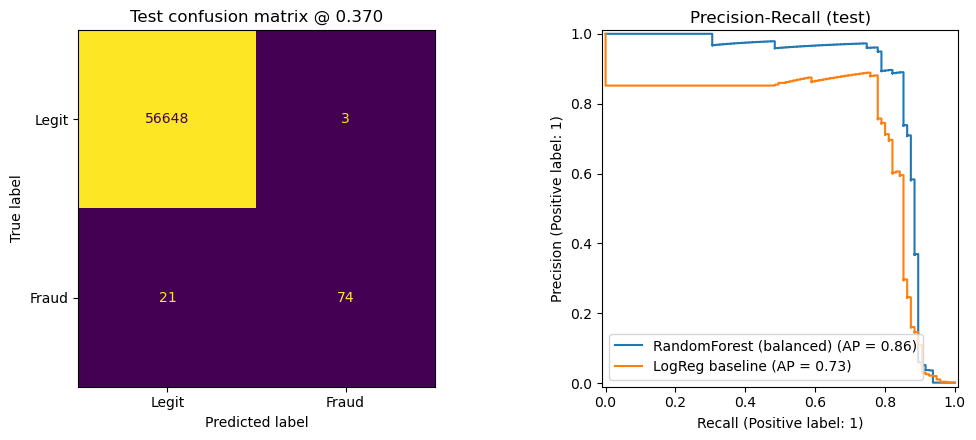

Saved: artifacts/fraud_model.joblib and artifacts/config.json


In [7]:
# %% [markdown]
# # Fraud Detection - Step 3 (v2): Explain, analyse errors, final test, save model
# Run in NEW cells BELOW Step 2 (v2) in the SAME notebook, in order. Do not restart the kernel in between.
# Reuses: df, X_train, X_val, X_test, y_train, y_val, y_test, best_name, best_model, thr_f1, thr_prec,
#         logreg, evaluate, SEED.
#
# Order matters:
#   - SHAP and error analysis use VALIDATION data only.
#   - The TEST set is used ONCE, in Cell 5, with a threshold chosen on validation.
#     If you change the model or threshold after seeing test numbers, the test set is no longer honest.

# %% [CELL 1] Imports, guard, chosen threshold
import json
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import xgboost as xgb
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay

os.makedirs("results", exist_ok=True)
os.makedirs("artifacts", exist_ok=True)

assert df.duplicated().sum() == 0, "df has duplicates - re-run Step 1 (v2) Cell 3, then Cells 5 onward."
assert len(X_train) + len(X_val) + len(X_test) == len(df), (
    "Stale split. Re-run Step 1 (v2) Cells 2, 3 and 5, then Step 2 (v2), then this step."
)
print("Guard passed. Total rows:", len(df), "| frauds:", int(df["Class"].sum()))

# The threshold we commit to BEFORE looking at the test set (chosen on validation in Step 2).
#   thr_f1   = best F1
#   thr_prec = highest recall with precision >= 80%
# Pick one and keep it.
CHOSEN_THRESHOLD = thr_f1
print(f"Model: {best_name} | chosen threshold: {CHOSEN_THRESHOLD:.3f}")

# %% [CELL 2] SHAP: which features drive the fraud score? (validation data)
# V1-V28 are anonymised PCA components, so SHAP shows WHICH components matter,
# not what they mean in business terms. Say this honestly in the README.
prep = best_model.named_steps["prep"]
clf = best_model.named_steps["clf"]

# ColumnTransformer output order: scaled Time, Amount first, then the other columns unchanged
feature_names = ["Time", "Amount"] + [c for c in X_train.columns if c not in ("Time", "Amount")]

# All validation frauds + a random sample of legit rows (keeps SHAP fast)
rng = np.random.RandomState(SEED)
yv = y_val.values
idx_fraud = np.where(yv == 1)[0]
idx_legit = rng.choice(np.where(yv == 0)[0], size=3000, replace=False)
idx = np.concatenate([idx_fraud, idx_legit])

X_shap = pd.DataFrame(prep.transform(X_val.iloc[idx]), columns=feature_names)

try:
    explainer = shap.TreeExplainer(clf)
    sv = explainer.shap_values(X_shap)
    if isinstance(sv, list):                    # some models return one array per class
        sv = sv[1]
    elif getattr(sv, "ndim", 2) == 3:
        sv = sv[:, :, 1]
except Exception as e:
    # Known version clashes between shap and xgboost: use XGBoost's built-in contributions instead
    print("TreeExplainer failed, using XGBoost native contributions. Reason:", repr(e)[:150])
    contribs = clf.get_booster().predict(xgb.DMatrix(X_shap, feature_names=feature_names), pred_contribs=True)
    sv = contribs[:, :-1]                       # last column is the bias term

plt.figure()
shap.summary_plot(sv, X_shap, show=False, max_display=15)
plt.tight_layout()
plt.savefig("results/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

plt.figure()
shap.summary_plot(sv, X_shap, plot_type="bar", show=False, max_display=15)
plt.tight_layout()
plt.savefig("results/shap_bar.png", dpi=150, bbox_inches="tight")
plt.show()

top = pd.Series(np.abs(sv).mean(axis=0), index=feature_names).sort_values(ascending=False).head(8)
print("Top features by mean |SHAP|:\n", top.round(4))

# %% [CELL 3] Error analysis on VALIDATION data
proba_val = best_model.predict_proba(X_val)[:, 1]
pred_val = (proba_val >= CHOSEN_THRESHOLD).astype(int)

err = X_val[["Time", "Amount"]].copy()
err["y_true"] = y_val.values
err["proba"] = proba_val
err["pred"] = pred_val

tp = err[(err.y_true == 1) & (err.pred == 1)]
fn = err[(err.y_true == 1) & (err.pred == 0)].sort_values("proba")
fp = err[(err.y_true == 0) & (err.pred == 1)].sort_values("proba", ascending=False)

print(f"Caught frauds (TP): {len(tp)} | Missed frauds (FN): {len(fn)} | False alarms (FP): {len(fp)}")
print("\nMissed frauds (lowest score first):")
print(fn.round(3).to_string())
print("\nFalse alarms (highest score first):")
print(fp.round(3).head(10).to_string())

print("\nAmount: caught frauds vs missed frauds")
print(pd.DataFrame({"caught": tp["Amount"].describe(), "missed": fn["Amount"].describe()}).round(2))
print("\nFraud scores of missed frauds (how close were they to the threshold?)")
print(fn["proba"].describe().round(3))

# %% [markdown]
# Questions to answer in your README (look at the tables above):
# - Are missed frauds mostly small amounts? Scored near zero, or just under the threshold?
# - Are false alarms large amounts? Is there a pattern in Time?
# - If a missed fraud costs more than a false alarm, would you lower the threshold?

# %% [CELL 4] FINAL evaluation on the TEST set (run this ONCE)
test_rows = [
    evaluate("LogReg baseline @ 0.50", logreg, X_test, y_test, 0.5),
    evaluate(f"{best_name} @ 0.50", best_model, X_test, y_test, 0.5),
    evaluate(f"{best_name} @ {CHOSEN_THRESHOLD:.3f} (chosen on val)", best_model, X_test, y_test, CHOSEN_THRESHOLD),
]
if thr_prec is not None:
    test_rows.append(evaluate(f"{best_name} @ {thr_prec:.3f} (precision>=80% on val)",
                              best_model, X_test, y_test, thr_prec))

test_df = pd.DataFrame(test_rows)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print(test_df[["model", "precision", "recall", "f1", "pr_auc", "roc_auc", "TP", "FP", "FN"]].to_string(index=False))
test_df.to_csv("results/step3_final_test_results.csv", index=False)

val_pr = evaluate("val", best_model, X_val, y_val, CHOSEN_THRESHOLD)["pr_auc"]
test_pr = evaluate("test", best_model, X_test, y_test, CHOSEN_THRESHOLD)["pr_auc"]
print(f"\nPR-AUC  validation: {val_pr:.4f} | test: {test_pr:.4f}")

# %% [CELL 5] Test plots: confusion matrix and PR curves
proba_test = best_model.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= CHOSEN_THRESHOLD).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["Legit", "Fraud"],
                                        colorbar=False, ax=axes[0])
axes[0].set_title(f"Test confusion matrix @ {CHOSEN_THRESHOLD:.3f}")
PrecisionRecallDisplay.from_estimator(best_model, X_test, y_test, name=best_name, ax=axes[1])
PrecisionRecallDisplay.from_estimator(logreg, X_test, y_test, name="LogReg baseline", ax=axes[1])
axes[1].set_title("Precision-Recall (test)")
plt.tight_layout()
plt.savefig("results/final_test_plots.png", dpi=150)
plt.show()

# %% [CELL 6] Save the model and threshold for deployment (Step 4)
joblib.dump(best_model, "artifacts/fraud_model.joblib")
with open("artifacts/config.json", "w") as f:
    json.dump({
        "model_name": best_name,
        "threshold": float(CHOSEN_THRESHOLD),
        "feature_order": list(X_train.columns),
    }, f, indent=2)
print("Saved: artifacts/fraud_model.joblib and artifacts/config.json")

In [8]:
import os
size_mb = os.path.getsize("artifacts/fraud_model.joblib") / (1024 * 1024)
print(f"Model size: {size_mb:.1f} MB")

Model size: 4.4 MB


In [9]:
import json
import os
import sys
import importlib.metadata as md
from pathlib import Path

import joblib

Path("artifacts").mkdir(exist_ok=True)

# 1) Save the model again with compression, then check its size
joblib.dump(best_model, "artifacts/fraud_model.joblib", compress=3)
size_mb = os.path.getsize("artifacts/fraud_model.joblib") / (1024 * 1024)
print(f"Model size: {size_mb:.1f} MB")
if size_mb > 100:
    print("Too big for GitHub (100 MB limit). Reduce n_estimators or use the XGBoost model instead.")

# 2) Sample transactions for the demo page (from VALIDATION data, not the test set)
proba_v = best_model.predict_proba(X_val)[:, 1]
caught_fraud = (y_val.values == 1) & (proba_v >= CHOSEN_THRESHOLD)
clear_legit = (y_val.values == 0) & (proba_v < 0.01)

samples = {
    "fraud": {k: float(v) for k, v in X_val[caught_fraud].iloc[0].items()},
    "legit": {k: float(v) for k, v in X_val[clear_legit].iloc[0].items()},
}
with open("artifacts/sample_transactions.json", "w") as f:
    json.dump(samples, f, indent=2)
print("Saved artifacts/sample_transactions.json")

# 3) requirements.txt pinned to your installed versions
def v(pkg):
    return md.version(pkg)

lines = [
    f"flask=={v('flask')}",
    "gunicorn",
    f"scikit-learn=={v('scikit-learn')}",
    f"pandas=={v('pandas')}",
    f"numpy=={v('numpy')}",
    f"joblib=={v('joblib')}",
]
mods = [type(best_model).__module__, type(best_model.named_steps["clf"]).__module__]
if any(m.startswith("xgboost") for m in mods):
    lines.append(f"xgboost=={v('xgboost')}")
if any(m.startswith("imblearn") for m in mods):
    lines.append(f"imbalanced-learn=={v('imbalanced-learn')}")

Path("requirements.txt").write_text("\n".join(lines) + "\n")
print("\nrequirements.txt:\n" + "\n".join(lines))
print("\nYour Python version:", sys.version.split()[0])
print("Model type:", best_name, "| threshold:", round(CHOSEN_THRESHOLD, 3))

Model size: 1.5 MB
Saved artifacts/sample_transactions.json

requirements.txt:
flask==3.1.2
gunicorn
scikit-learn==1.7.2
pandas==2.3.3
numpy==2.3.5
joblib==1.5.2

Your Python version: 3.13.9
Model type: RandomForest (balanced) | threshold: 0.37
